# 02 — Time Factors and Collision Severity (Member 1)
**Project:** Predicting Road Accident Severity Using Data Science — Milestone 1 · **Report section:** IV-D

Question: does the share of collisions that are KSI (killed or seriously injured) change with the **hour, day, month and rush hour**,
and is the pattern the same in 2024 and 2025?

Input: `UK_Road_Accidents_Cleaned_2024_2025.csv` (Member 3's cleaned file). The time columns have no missing values.
Tests: chi-square test of independence with Cramér's V (effect size) and two-proportion z-tests, α = 0.05.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/Road_Accident_Project"
except ImportError:
    DATA_DIR = "."

df = pd.read_csv(os.path.join(DATA_DIR, "UK_Road_Accidents_Cleaned_2024_2025.csv"), low_memory=False)
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["weekday"] = pd.Categorical(df["weekday"], WEEKDAYS, ordered=True)
df["time_band"] = pd.Categorical(df["time_band"], ["Night", "Morning", "Afternoon", "Evening"], ordered=True)
print(df.shape)
print("Missing values in time columns:", df[["hour", "weekday", "month", "time_band", "rush_hour", "is_weekend"]].isna().sum().sum())

(202452, 52)
Missing values in time columns: 0


## 1. Collisions and KSI rate by hour

In [2]:
by_hour = df.groupby("hour").agg(collisions=("KSI", "size"), KSI_rate=("KSI", "mean"))
by_hour["KSI_rate"] = (by_hour["KSI_rate"] * 100).round(2)
by_hour["share_of_collisions_%"] = (by_hour["collisions"] / len(df) * 100).round(2)
by_hour

,collisions,KSI_rate,share_of_collisions_%
hour,,,
0,3171,32.20,1.57
1,2096,31.39,1.04
2,1563,31.54,0.77
3,1293,30.70,0.64
4,1224,31.21,0.60
5,1892,28.81,0.93
6,3830,27.96,1.89
7,8309,24.03,4.10
8,13319,20.40,6.58


In [3]:
peak = by_hour["collisions"].idxmax()
print(f"Most collisions: {peak}:00 ({by_hour.loc[peak, 'collisions']:,})")
print(f"Highest KSI rate: {by_hour['KSI_rate'].idxmax()}:00 ({by_hour['KSI_rate'].max():.2f}%)")
print(f"Lowest KSI rate:  {by_hour['KSI_rate'].idxmin()}:00 ({by_hour['KSI_rate'].min():.2f}%)")

Most collisions: 17:00 (17,661)
Highest KSI rate: 0:00 (32.20%)
Lowest KSI rate:  8:00 (20.40%)


## 2. KSI rate by time band, weekday, month, rush hour and weekend

In [4]:
def ksi_table(col):
    t = df.groupby(col, observed=True).agg(collisions=("KSI", "size"), KSI_rate=("KSI", "mean"))
    t["KSI_rate"] = (t["KSI_rate"] * 100).round(2)
    return t

for col in ["time_band", "weekday", "month", "rush_hour", "is_weekend"]:
    print(ksi_table(col), "\n")

           collisions  KSI_rate
time_band                      
Night           11239     31.11
Morning         53483     23.71
Afternoon       88002     24.91
Evening         49728     27.37 

           collisions  KSI_rate
weekday                        
Monday          28360     24.92
Tuesday         29777     24.26
Wednesday       30284     24.69
Thursday        30765     24.55
Friday          33255     25.08
Saturday        27426     27.82
Sunday          22585     28.43 

       collisions  KSI_rate
month                      
1           16464     23.92
2           14692     24.07
3           16264     24.97
4           15961     26.01
5           17832     26.24
6           17789     26.54
7           17267     25.99
8           16509     28.35
9           17419     25.70
10          17682     24.84
11          18107     24.04
12          16466     25.71 

           collisions  KSI_rate
rush_hour                      
0              137118     26.76
1               65334     

## 3. Hypothesis tests
* **H6a** — KSI depends on the hour of day (chi-square).
* **H6b** — KSI depends on the day of the week (chi-square).
* **H6c** — KSI depends on the month (chi-square).
* **H6d** — Rush-hour collisions have a different KSI rate from other collisions (two-proportion z-test).
* **H6e** — Weekend collisions have a different KSI rate from weekday collisions (two-proportion z-test).

In [5]:
def chi_test(col):
    table = pd.crosstab(df[col], df["KSI"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return chi2, dof, p, v

def z_test(a, b):
    p1, p2 = a.mean(), b.mean()
    p = (a.sum() + b.sum()) / (len(a) + len(b))
    z = (p1 - p2) / np.sqrt(p * (1 - p) * (1 / len(a) + 1 / len(b)))
    return z, 2 * stats.norm.sf(abs(z)), p1, p2

rows = []
for h, col in [("H6a", "hour"), ("H6b", "weekday"), ("H6c", "month"), ("—", "time_band")]:
    chi2, dof, p, v = chi_test(col)
    rows.append([h, col, "Chi-square", f"χ²({dof}) = {chi2:.1f}", p, f"V = {v:.3f}"])

for h, col in [("H6d", "rush_hour"), ("H6e", "is_weekend")]:
    z, p, p1, p0 = z_test(df.loc[df[col] == 1, "KSI"], df.loc[df[col] == 0, "KSI"])
    rows.append([h, col, "Two-proportion z", f"z = {z:.2f}", p, f"{p1*100:.2f}% vs {p0*100:.2f}%"])

tests = pd.DataFrame(rows, columns=["H", "Variable", "Test", "Statistic", "p", "Effect"])
tests["Decision"] = np.where(tests["p"] < 0.05, "Reject H0", "Fail to reject H0")
tests["p"] = tests["p"].map(lambda x: "< 0.001" if x < 0.001 else f"{x:.3f}")
tests

,H,Variable,Test,Statistic,p,Effect,Decision
0,H6a,hour,Chi-square,χ²(23) = 647.5,< 0.001,V = 0.057,Reject H0
1,H6b,weekday,Chi-square,χ²(6) = 237.0,< 0.001,V = 0.034,Reject H0
2,H6c,month,Chi-square,χ²(11) = 154.7,< 0.001,V = 0.028,Reject H0
3,—,time_band,Chi-square,χ²(3) = 383.0,< 0.001,V = 0.043,Reject H0
4,H6d,rush_hour,Two-proportion z,z = -18.25,< 0.001,22.98% vs 26.76%,Reject H0
5,H6e,is_weekend,Two-proportion z,z = 15.10,< 0.001,28.10% vs 24.71%,Reject H0


## 4. 2024 vs 2025 by time band
Recorded KSI and severity-adjusted KSI (`KSI_adjusted`), because injury-based reporting grew from 58.8% to 86.5% of collisions.

In [6]:
year_band = (df.pivot_table(index="time_band", columns="collision_year", values=["KSI", "KSI_adjusted"],
                            aggfunc="mean", observed=True) * 100).round(2)
year_band[("KSI", "change")] = (year_band[("KSI", 2025)] - year_band[("KSI", 2024)]).round(2)
year_band[("KSI_adjusted", "change")] = (year_band[("KSI_adjusted", 2025)] - year_band[("KSI_adjusted", 2024)]).round(2)
year_band = year_band[[("KSI", 2024), ("KSI", 2025), ("KSI", "change"),
                       ("KSI_adjusted", 2024), ("KSI_adjusted", 2025), ("KSI_adjusted", "change")]]
year_band

KSI               KSI_adjusted              
collision_year   2024   2025 change         2024   2025 change
time_band                                                     
Night           30.11  32.12   2.01        31.49  32.76   1.27
Morning         23.33  24.10   0.77        24.41  24.60   0.19
Afternoon       24.10  25.70   1.60        25.21  26.27   1.06
Evening         26.54  28.22   1.68        27.66  28.75   1.09

In [7]:
# Is the hourly pattern the same in both years? Correlation of the 24 hourly KSI rates
hour_year = df.pivot_table(index="hour", columns="collision_year", values="KSI", aggfunc="mean") * 100
r = hour_year[2024].corr(hour_year[2025])
print(f"Correlation of hourly KSI rates, 2024 vs 2025: r = {r:.2f}")
hour_year.round(1).T

Correlation of hourly KSI rates, 2024 vs 2025: r = 0.93


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
collision_year,,,,,,,,,,,,,,,,,,,,,
2024,31.7,30.0,30.7,29.8,29.2,27.9,28.6,24.5,19.4,23.1,...,24.5,23.4,23.7,23.7,23.4,25.4,27.4,28.4,29.8,30.7
2025,32.8,32.8,32.3,31.6,33.1,29.7,27.3,23.6,21.4,23.2,...,26.3,25.6,25.5,25.3,27.2,26.3,28.0,29.8,31.0,30.4


## 5. Fig. 2 — collisions and KSI rate by hour of day

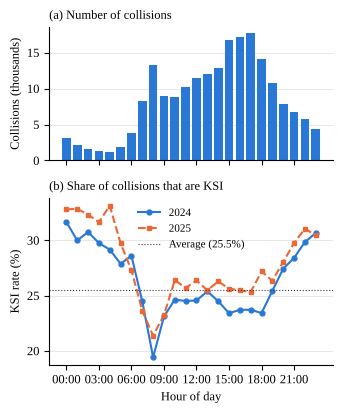

In [8]:
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GRID, INK = "#2a78d6", "#eb6834", "#e4e3df", "#3d3d3a"
hours = np.arange(24)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(3.5, 4.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.25]})

# (a) number of collisions per hour, both years combined
ax1.bar(hours, by_hour["collisions"] / 1000, width=0.8, color=BLUE)
ax1.set_ylabel("Collisions (thousands)")
ax1.set_title("(a) Number of collisions", loc="left", fontsize=9)
ax1.grid(axis="y", color=GRID, linewidth=0.6); ax1.set_axisbelow(True)

# (b) KSI rate per hour, one line per year (different markers and dashes for greyscale printing)
ax2.plot(hours, hour_year[2024], color=BLUE, marker="o", markersize=3.5, linewidth=1.5, label="2024")
ax2.plot(hours, hour_year[2025], color=ORANGE, marker="s", markersize=3.5, linewidth=1.5, linestyle="--", label="2025")
ax2.axhline(df["KSI"].mean() * 100, color=INK, linewidth=0.8, linestyle=":", label=f"Average ({df['KSI'].mean()*100:.1f}%)")
ax2.set_ylabel("KSI rate (%)")
ax2.set_xlabel("Hour of day")
ax2.set_title("(b) Share of collisions that are KSI", loc="left", fontsize=9)
ax2.set_xticks(range(0, 24, 3))
ax2.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 3)])
ax2.legend(frameon=False, loc="upper center", fontsize=8)
ax2.grid(axis="y", color=GRID, linewidth=0.6); ax2.set_axisbelow(True)

fig.tight_layout()
fig.savefig(os.path.join(DATA_DIR, "fig2_ksi_by_hour.png"), dpi=300, bbox_inches="tight")
plt.show()

## 6. Numbers for the report (Section IV-D)

In [9]:
tb = ksi_table("time_band")
wd = ksi_table("weekday")
print(f"Busiest hour: {peak}:00. The three hours 15:00–17:59 hold {by_hour.loc[15:17, 'collisions'].sum()/len(df)*100:.1f}% of all collisions.")
print(f"KSI rate 00:00–04:59: {df.loc[df['hour'] <= 4, 'KSI'].mean()*100:.1f}%  |  at 08:00: {by_hour.loc[8, 'KSI_rate']:.1f}%")
print(f"Night (00–05) = {tb.loc['Night', 'collisions']/len(df)*100:.1f}% of collisions, KSI {tb.loc['Night', 'KSI_rate']:.2f}%; "
      f"Morning KSI {tb.loc['Morning', 'KSI_rate']:.2f}%")
print(f"Weekday range {wd['KSI_rate'].iloc[:5].min():.2f}–{wd['KSI_rate'].iloc[:5].max():.2f}%, Saturday {wd.loc['Saturday','KSI_rate']:.2f}%, Sunday {wd.loc['Sunday','KSI_rate']:.2f}%")
print(tests[["H", "Statistic", "p", "Effect"]].to_string(index=False))

Busiest hour: 17:00. The three hours 15:00–17:59 hold 25.5% of all collisions.
KSI rate 00:00–04:59: 31.6%  |  at 08:00: 20.4%
Night (00–05) = 5.6% of collisions, KSI 31.11%; Morning KSI 23.71%
Weekday range 24.26–25.08%, Saturday 27.82%, Sunday 28.43%
  H      Statistic       p           Effect
H6a χ²(23) = 647.5 < 0.001        V = 0.057
H6b  χ²(6) = 237.0 < 0.001        V = 0.034
H6c χ²(11) = 154.7 < 0.001        V = 0.028
  —  χ²(3) = 383.0 < 0.001        V = 0.043
H6d     z = -18.25 < 0.001 22.98% vs 26.76%
H6e      z = 15.10 < 0.001 28.10% vs 24.71%
